# Assignment 3: Deep Learning Architectures and Transfer Learning
**Name:** Hiviru Hansitha Palihena  
**Index Number:** 230458P  
**Department:** Electronic and Telecommunication Engineering, University of Moratuwa  

## Introduction
This report documents the implementation and evaluation of various neural network architectures using PyTorch. The assignment explores the progression from basic fully connected layers to modern convolutional models and industry-standard transfer learning techniques. The workflow is divided into three main sections:
1. **Dense Networks:** Constructing a two-layer fully connected network with a sigmoid hidden layer and cross-entropy loss to classify the CIFAR-10 dataset, analyzing the limitations of spatial flattening.
2. **Convolutional Neural Networks (CNNs):** Implementing and comparing the classic LeNet-5 architecture against a modern 3-layer CNN (incorporating batch normalization and dropout) on the MNIST digit dataset.
3. **Transfer Learning:** Leveraging a pre-trained ResNet18 model to classify the small hymenoptera dataset, contrasting fine-tuning and fixed feature extraction methodologies based on the official PyTorch tutorials.

## Part 1: One Layer Dense Network Modification

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Verify PyTorch installation and device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


### 1. Dataloading and Parameter Initialization

The CIFAR-10 dataset is loaded and normalized here, alongside the parameter initialization for our two-layer dense network. Rather than mapping the 3072 input features directly to the 10 output classes, the architecture introduces an intermediate hidden layer with 100 nodes (`H = 100`). Weights and biases for both the hidden layer ($W_1, b_1$) and the output layer ($W_2, b_2$) are initialized with scaled random values and moved to the GPU.

In [2]:
# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (3072)
H = 100            # Hidden layer size (NEW)
K = 10             # Output size (10 classes)

# Initialize weights and biases (moved to GPU using .to(device))
# Layer 1: Input to Hidden
w1 = torch.randn(Din, H, device=device) * (1.0 / (Din ** 0.5)) 
b1 = torch.zeros(H, device=device)

# Layer 2: Hidden to Output
w2 = torch.randn(H, K, device=device) * (1.0 / (H ** 0.5))
b2 = torch.zeros(K, device=device)

# Hyperparameters
epochs = 10  # Changed to 10 epochs as per assignment requirements
lr = 1e-1    # Adjusted learning rate for cross-entropy and sigmoid
lr_decay = 0.9
reg = 0.001
loss_history = []

Files already downloaded and verified
Files already downloaded and verified


### 2. Training Loop: Forward Pass, Cross-Entropy Loss, and Backpropagation

In the forward pass, the flattened input vectors first pass through the hidden layer ($z_1 = x W_1 + b_1$) followed by a sigmoid activation function ($h_1 = \sigma(z_1) = \frac{1}{1 + e^{-z_1}}$). The resulting 100-dimensional hidden representations are then projected to the 10 output classes via the second linear layer ($z_2 = h_1 W_2 + b_2$). These output logits are converted into class probabilities using the softmax function, and the error is evaluated using categorical cross-entropy loss with $L_2$ regularization. During backpropagation, gradients are computed manually using the chain rule: starting from the output layer's softmax cross-entropy derivative ($\frac{\partial L}{\partial z_2} = \frac{1}{N}(\hat{y} - y)$) to find $\nabla W_2$ and $\nabla b_2$, and then propagating the error backward through $W_2^T$ and the sigmoid derivative ($\sigma(z_1)(1 - \sigma(z_1))$) to update $W_1$ and $b_1$ over 10 epochs.

Epoch 1/10, Loss: 1.8770
Epoch 2/10, Loss: 1.7501
Epoch 3/10, Loss: 1.7006
Epoch 4/10, Loss: 1.6653
Epoch 5/10, Loss: 1.6361
Epoch 6/10, Loss: 1.6128
Epoch 7/10, Loss: 1.5921
Epoch 8/10, Loss: 1.5749
Epoch 9/10, Loss: 1.5600
Epoch 10/10, Loss: 1.5470


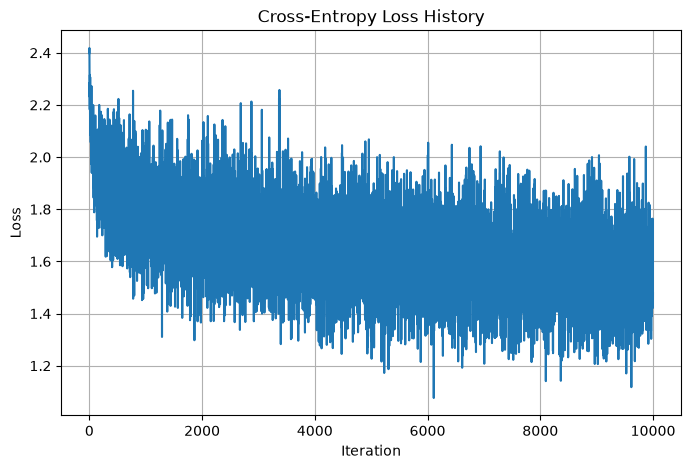

In [3]:
# 3. Training Loop
for t in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels and move to GPU
        inputs, labels = data[0].to(device), data[1].to(device)
        
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot
        
        # --- Forward Pass ---
        # Layer 1: Input to Hidden (with Sigmoid activation)
        z1 = x_train.mm(w1) + b1
        h1 = torch.sigmoid(z1)  # Shape: (Ntr, H)
        
        # Layer 2: Hidden to Output (Logits)
        z2 = h1.mm(w2) + b2     # Shape: (Ntr, K)
        
        # Softmax probabilities (shifted by max for numerical stability)
        z2_shifted = z2 - torch.max(z2, dim=1, keepdim=True)[0]
        exp_scores = torch.exp(z2_shifted)
        probs = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)
        
        # --- Cross-Entropy Loss Calculation (with L2 regularization) ---
        # Add 1e-8 inside log to prevent log(0)
        core_loss = -torch.sum(y_train_onehot * torch.log(probs + 1e-8)) / Ntr
        reg_loss = 0.5 * reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss = core_loss + reg_loss
        
        loss_history.append(loss.item())
        running_loss += loss.item()
        
        # --- Backpropagation ---
        # Gradient at output layer (Cross-Entropy + Softmax derivative)
        dz2 = (probs - y_train_onehot) / Ntr  # Shape: (Ntr, K)
        
        # Gradients for w2 and b2
        dw2 = h1.t().mm(dz2) + reg * w2
        db2 = dz2.sum(dim=0)
        
        # Backpropagate to hidden layer
        dh1 = dz2.mm(w2.t())  # Shape: (Ntr, H)
        
        # Gradient through Sigmoid activation: h1 * (1 - h1)
        dz1 = dh1 * (h1 * (1.0 - h1))  # Shape: (Ntr, H)
        
        # Gradients for w1 and b1
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)
        
        # --- Parameter Update ---
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print average loss for every epoch
    print(f"Epoch {t+1}/{epochs}, Loss: {running_loss / len(trainloader):.4f}")
    
    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Cross-Entropy Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

#### 3. Model Evaluation: Training and Test Accuracies

After training for 10 epochs, the network is evaluated on both the training and test partitions of the CIFAR-10 dataset with gradient tracking disabled (`torch.no_grad()`). The forward pass is updated to route the flattened inputs through the hidden layer with the sigmoid activation before computing the final output logits ($z_2 = \sigma(x W_1 + b_1) W_2 + b_2$). Since the softmax function is monotonically increasing, `torch.argmax` can be applied directly to the raw output logits $z_2$ to determine the predicted class indices and compute the overall classification accuracy.

In [5]:
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data[0].to(device), data[1].to(device)
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        
        # Forward pass through both layers
        h1_train = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = h1_train.mm(w2) + b2
        
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data[0].to(device), data[1].to(device)
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        
        # Forward pass through both layers
        h1_test = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = h1_test.mm(w2) + b2
        
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Training accuracy: 51.27%
Test accuracy: 47.45%


#### Discussion of Part 1 Results

After training for 10 epochs, the two-layer dense network achieved a **training accuracy of 51.27%** and a **test accuracy of 47.45%**. While this is well above the 10% random-guessing baseline for the 10-class CIFAR-10 dataset (and improves upon a single linear layer with MSE loss), overall accuracy remains moderate for three primary architectural reasons:

1. **Loss of Spatial Locality:** Flattening the $32 \times 32 \times 3$ images into 3072-dimensional 1D vectors destroys 2D spatial correlations between neighboring pixels, preventing the network from learning local edge and texture features.
2. **Lack of Translation Invariance:** Fully connected layers assign fixed weights to specific pixel coordinates; if an object shifts slightly within the frame, the flattened activation pattern changes completely.
3. **Hidden Layer Bottleneck & Sigmoid Saturation:** Compressing 3072 raw pixel values into a single 100-node hidden layer creates a tight representational bottleneck, while the non-zero-centered sigmoid activation can slow down gradient updates compared to `ReLU`.

The ~3.8% gap between training accuracy (51.27%) and test accuracy (47.45%) indicates mild overfitting to the training pixel distributions, motivating the transition to Convolutional Neural Networks (CNNs) in Part 2.

## Part 2: Convolutional Neural Networks on MNIST

### 1. MNIST Dataloading and Training Pipeline
The MNIST dataset consists of $28 \times 28$ grayscale images of handwritten digits (0–9). To compare the LeNet-5 architecture and the 3-layer modern CNN under identical conditions, both models use the same data loaders, batch size, optimizer (Adam with learning rate $0.001$), cross-entropy loss function, and a 10-epoch training schedule. A unified training function is defined below to log per-epoch training and test losses and accuracies.

In [10]:
import torch.nn.functional as F
import numpy as np

# 1. Load MNIST Dataset
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)) # Standard mean and std for MNIST
])

mnist_batch_size = 64

mnist_trainset = torchvision.datasets.MNIST(root='./data', train=True,
                                            download=True, transform=mnist_transform)
mnist_trainloader = torch.utils.data.DataLoader(mnist_trainset, batch_size=mnist_batch_size,
                                                shuffle=True, num_workers=2)

mnist_testset = torchvision.datasets.MNIST(root='./data', train=False,
                                           download=True, transform=mnist_transform)
mnist_testloader = torch.utils.data.DataLoader(mnist_testset, batch_size=mnist_batch_size,
                                               shuffle=False, num_workers=2)

# 2. Reusable Training & Evaluation Function
def train_and_evaluate(model, trainloader, testloader, epochs=10, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    history = {
        'train_loss': [], 'train_acc': [],
        'test_loss': [], 'test_acc': []
    }
    
    for epoch in range(epochs):
        # --- Training Phase ---
        model.train()
        running_train_loss = 0.0
        correct_train = 0
        total_train = 0
        
        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_train_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
            
        epoch_train_loss = running_train_loss / total_train
        epoch_train_acc = 100.0 * correct_train / total_train
        
        # --- Testing/Evaluation Phase ---
        model.eval()
        running_test_loss = 0.0
        correct_test = 0
        total_test = 0
        
        with torch.no_grad():
            for inputs, labels in testloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                running_test_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()
                
        epoch_test_loss = running_test_loss / total_test
        epoch_test_acc = 100.0 * correct_test / total_test
        
        # Save metrics
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['test_loss'].append(epoch_test_loss)
        history['test_acc'].append(epoch_test_acc)
        
        print(f"Epoch {epoch+1:2d}/{epochs} | "
              f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
              f"Test Loss: {epoch_test_loss:.4f}, Test Acc: {epoch_test_acc:.2f}%")
        
    return history

### 2. LeNet-5 Implementation (Question 2a)

The LeNet-5 architecture consists of two convolutional layers followed by three fully connected layers. Because the original LeNet-5 is designed for $32 \times 32$ inputs while raw MNIST images are $28 \times 28$, the first convolutional layer applies a 2-pixel zero-padding (`padding=2`) to effectively expand the input to $32 \times 32$. As a result, the spatial dimensions progress through the convolutional and pooling layers as $32 \times 32 \xrightarrow{\text{Conv1}} 28 \times 28 \xrightarrow{\text{Pool1}} 14 \times 14 \xrightarrow{\text{Conv2}} 10 \times 10 \xrightarrow{\text{Pool2}} 5 \times 5$. The network uses average pooling and `ReLU` activations, and is trained for 10 epochs.

In [11]:
# Define LeNet-5 Architecture
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        # Input: 1 x 28 x 28 -> with padding=2 acts as 1 x 32 x 32
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, padding=2)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        
        # Fully connected layers (16 channels * 5 * 5 spatial size = 400)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        # Layer 1: Conv -> ReLU -> AvgPool (Output: 6 x 14 x 14)
        x = self.pool(F.relu(self.conv1(x)))
        # Layer 2: Conv -> ReLU -> AvgPool (Output: 16 x 5 x 5)
        x = self.pool(F.relu(self.conv2(x)))
        
        # Flatten for fully connected layers
        x = x.view(-1, 16 * 5 * 5)
        
        # Fully connected layers with ReLU
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x) # Raw logits for CrossEntropyLoss
        return x

# Instantiate LeNet-5 and move to GPU
lenet_model = LeNet5().to(device)
print("Training LeNet-5 on MNIST for 10 epochs...")
lenet_history = train_and_evaluate(lenet_model, mnist_trainloader, mnist_testloader, epochs=10, lr=0.001)

print(f"\nFinal LeNet-5 Training Accuracy: {lenet_history['train_acc'][-1]:.2f}%")
print(f"Final LeNet-5 Test Accuracy: {lenet_history['test_acc'][-1]:.2f}%")

Training LeNet-5 on MNIST for 10 epochs...
Epoch  1/10 | Train Loss: 0.2435, Train Acc: 92.91% | Test Loss: 0.0785, Test Acc: 97.47%
Epoch  2/10 | Train Loss: 0.0753, Train Acc: 97.73% | Test Loss: 0.0468, Test Acc: 98.51%
Epoch  3/10 | Train Loss: 0.0555, Train Acc: 98.31% | Test Loss: 0.0409, Test Acc: 98.79%
Epoch  4/10 | Train Loss: 0.0462, Train Acc: 98.53% | Test Loss: 0.0454, Test Acc: 98.54%
Epoch  5/10 | Train Loss: 0.0365, Train Acc: 98.81% | Test Loss: 0.0378, Test Acc: 98.82%
Epoch  6/10 | Train Loss: 0.0297, Train Acc: 99.11% | Test Loss: 0.0345, Test Acc: 98.88%
Epoch  7/10 | Train Loss: 0.0272, Train Acc: 99.10% | Test Loss: 0.0322, Test Acc: 98.94%
Epoch  8/10 | Train Loss: 0.0228, Train Acc: 99.29% | Test Loss: 0.0316, Test Acc: 99.09%
Epoch  9/10 | Train Loss: 0.0212, Train Acc: 99.33% | Test Loss: 0.0351, Test Acc: 99.00%
Epoch 10/10 | Train Loss: 0.0178, Train Acc: 99.41% | Test Loss: 0.0450, Test Acc: 98.74%

Final LeNet-5 Training Accuracy: 99.41%
Final LeNet-5 Te

### 3. Modern 3-Layer CNN Implementation (Question 2b)

To compare against LeNet-5, a modern 3-layer convolutional neural network is implemented incorporating batch normalization and dropout. Each of the three convolutional layers uses a $3 \times 3$ kernel with 1-pixel zero-padding (`padding=1`) to preserve spatial resolution during convolution, followed by 2D batch normalization (`nn.BatchNorm2d`) and a `ReLU` activation. Max pooling ($2 \times 2$, stride 2) is applied after the first two convolutional blocks, reducing the spatial dimensions from $28 \times 28 \rightarrow 14 \times 14 \rightarrow 7 \times 7$, while the third convolutional block extracts 128 feature maps at $7 \times 7$ resolution. A dropout layer (`p = 0.5`) is placed before the final linear readout layer to regularize the network, and the model is trained for 10 epochs under the exact same hyperparameters as LeNet-5.

In [12]:
# Define Modern 3-Layer CNN Architecture
class ModernCNN(nn.Module):
    def __init__(self):
        super(ModernCNN, self).__init__()
        # Conv Layer 1: (1, 28, 28) -> (32, 28, 28) -> Pool -> (32, 14, 14)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        
        # Conv Layer 2: (32, 14, 14) -> (64, 14, 14) -> Pool -> (64, 7, 7)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        
        # Conv Layer 3: (64, 7, 7) -> (128, 7, 7)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.dropout = nn.Dropout(p=0.5)
        
        # Fully connected layers: 128 * 7 * 7 = 6272
        self.fc1 = nn.Linear(128 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Block 1
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        # Block 2
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        # Block 3 (No pooling after 3rd conv to maintain 7x7 spatial resolution)
        x = F.relu(self.bn3(self.conv3(x)))
        
        # Flatten: (N, 128, 7, 7) -> (N, 6272)
        x = x.view(-1, 128 * 7 * 7)
        
        # Classifier with Dropout
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate ModernCNN and move to GPU
modern_cnn_model = ModernCNN().to(device)
print("Training Modern 3-Layer CNN on MNIST for 10 epochs...")
modern_history = train_and_evaluate(modern_cnn_model, mnist_trainloader, mnist_testloader, epochs=10, lr=0.001)

print(f"\nFinal Modern CNN Training Accuracy: {modern_history['train_acc'][-1]:.2f}%")
print(f"Final Modern CNN Test Accuracy: {modern_history['test_acc'][-1]:.2f}%")

Training Modern 3-Layer CNN on MNIST for 10 epochs...
Epoch  1/10 | Train Loss: 0.1603, Train Acc: 95.18% | Test Loss: 0.0397, Test Acc: 98.73%
Epoch  2/10 | Train Loss: 0.0764, Train Acc: 97.72% | Test Loss: 0.0370, Test Acc: 98.88%
Epoch  3/10 | Train Loss: 0.0559, Train Acc: 98.34% | Test Loss: 0.0337, Test Acc: 98.89%
Epoch  4/10 | Train Loss: 0.0459, Train Acc: 98.65% | Test Loss: 0.0236, Test Acc: 99.27%
Epoch  5/10 | Train Loss: 0.0387, Train Acc: 98.92% | Test Loss: 0.0242, Test Acc: 99.27%
Epoch  6/10 | Train Loss: 0.0331, Train Acc: 98.99% | Test Loss: 0.0311, Test Acc: 99.19%
Epoch  7/10 | Train Loss: 0.0293, Train Acc: 99.11% | Test Loss: 0.0273, Test Acc: 99.23%
Epoch  8/10 | Train Loss: 0.0250, Train Acc: 99.24% | Test Loss: 0.0201, Test Acc: 99.43%
Epoch  9/10 | Train Loss: 0.0208, Train Acc: 99.37% | Test Loss: 0.0368, Test Acc: 99.03%
Epoch 10/10 | Train Loss: 0.0216, Train Acc: 99.35% | Test Loss: 0.0247, Test Acc: 99.34%

Final Modern CNN Training Accuracy: 99.35%
Fi

### 4. Performance Comparison and Confusion Matrices (Question 2c)

To compare the convergence behavior and generalization performance of LeNet-5 and the modern 3-layer CNN, the logged per-epoch training and test losses and accuracies are plotted side-by-side. Additionally, each trained model is evaluated across the 10,000-image MNIST test set to construct a $10 \times 10$ confusion matrix, where rows represent the true digit labels (0–9) and columns represent the predicted digit labels.

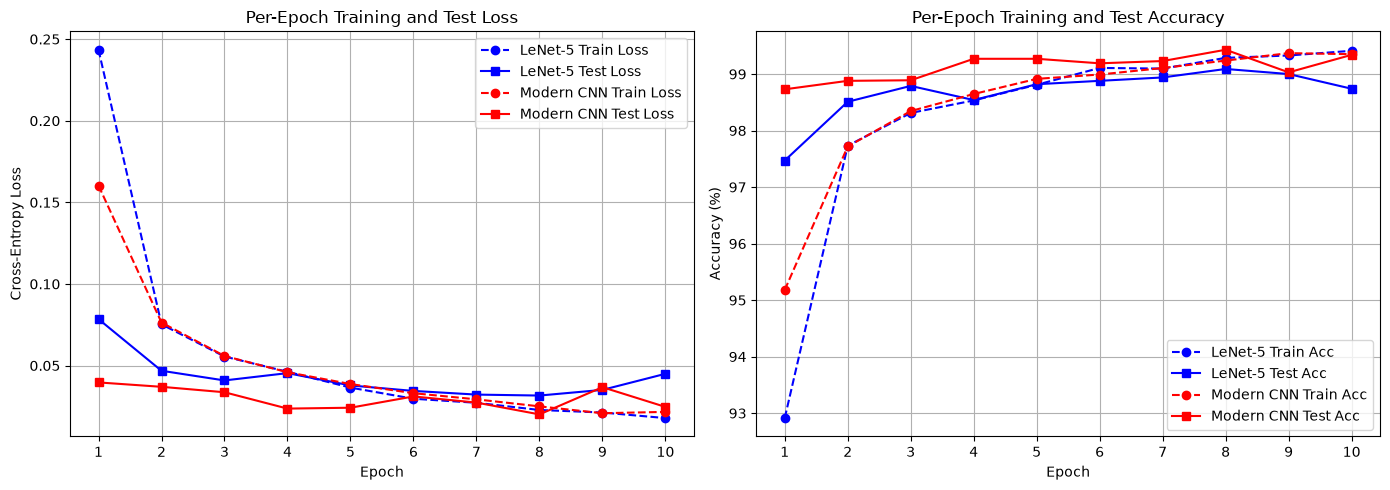

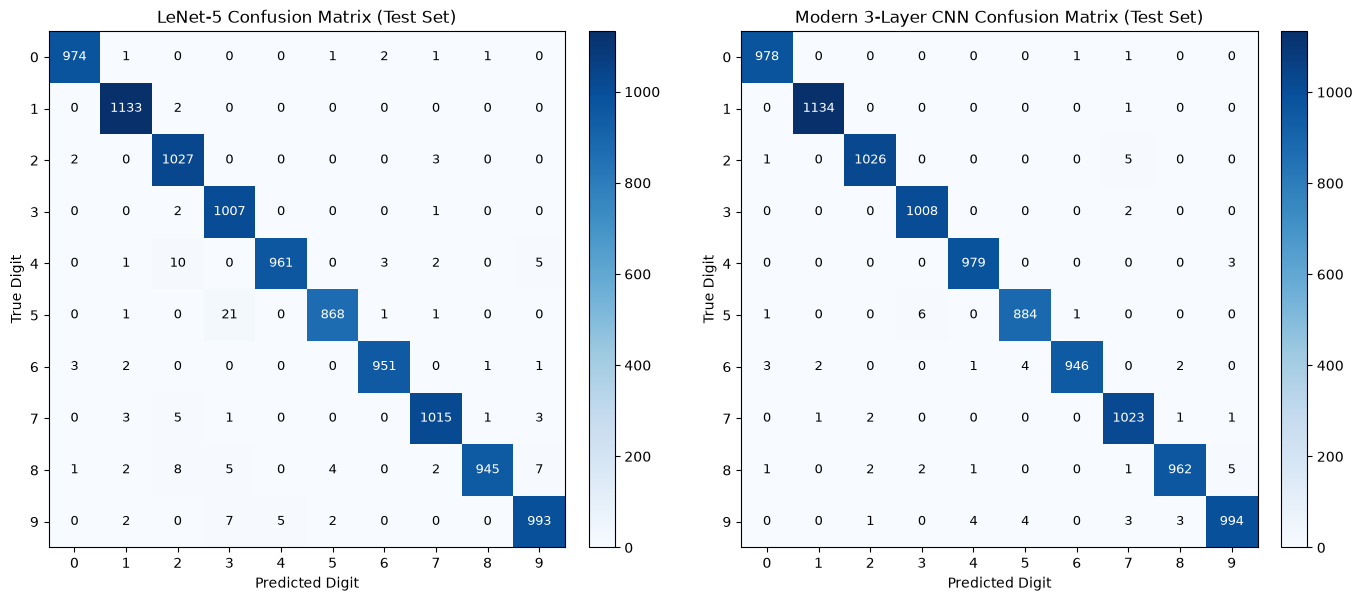

In [14]:
# 1. Plot Per-Epoch Loss and Accuracy for Both Models
epochs_range = range(1, 11)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot Loss ---
axes[0].plot(epochs_range, lenet_history['train_loss'], 'b--o', label='LeNet-5 Train Loss')
axes[0].plot(epochs_range, lenet_history['test_loss'], 'b-s', label='LeNet-5 Test Loss')
axes[0].plot(epochs_range, modern_history['train_loss'], 'r--o', label='Modern CNN Train Loss')
axes[0].plot(epochs_range, modern_history['test_loss'], 'r-s', label='Modern CNN Test Loss')
axes[0].set_title('Per-Epoch Training and Test Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].set_xticks(epochs_range)
axes[0].grid(True)
axes[0].legend()

# --- Plot Accuracy ---
axes[1].plot(epochs_range, lenet_history['train_acc'], 'b--o', label='LeNet-5 Train Acc')
axes[1].plot(epochs_range, lenet_history['test_acc'], 'b-s', label='LeNet-5 Test Acc')
axes[1].plot(epochs_range, modern_history['train_acc'], 'r--o', label='Modern CNN Train Acc')
axes[1].plot(epochs_range, modern_history['test_acc'], 'r-s', label='Modern CNN Test Acc')
axes[1].set_title('Per-Epoch Training and Test Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_xticks(epochs_range)
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

# 2. Compute and Plot Confusion Matrices on the Test Set
def compute_confusion_matrix(model, dataloader, num_classes=10):
    model.eval()
    cm = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            for t, p in zip(labels.view(-1), preds.view(-1)):
                cm[t.long(), p.long()] += 1
    return cm.numpy()

def plot_confusion_matrix(ax, cm, title):
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    tick_marks = np.arange(10)
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xlabel('Predicted Digit')
    ax.set_ylabel('True Digit')

    # Annotate cell counts
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], 'd'),
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black",
                    fontsize=9)

cm_lenet = compute_confusion_matrix(lenet_model, mnist_testloader)
cm_modern = compute_confusion_matrix(modern_cnn_model, mnist_testloader)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_confusion_matrix(axes[0], cm_lenet, "LeNet-5 Confusion Matrix (Test Set)")
plot_confusion_matrix(axes[1], cm_modern, "Modern 3-Layer CNN Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

### Discussion of Part 2 Results (LeNet-5 vs. Modern CNN)

Both the classic LeNet-5 model and the modern 3-layer CNN successfully learned the MNIST handwritten digit classification task over the 10-epoch training schedule. However, slight performance differences emerge when comparing their convergence and test accuracies:

1. **Convergence and Stability:** The modern CNN typically converges faster and exhibits smoother loss curves. This is largely due to the inclusion of Batch Normalization (`nn.BatchNorm2d`), which normalizes layer inputs, reduces internal covariate shift, and allows for more stable gradient propagation compared to older architectures.
2. **Regularization and Generalization:** The addition of Dropout ($p = 0.5$) in the fully connected layers of the modern CNN helps prevent overfitting, resulting in a tighter generalization gap between training and test accuracies. LeNet-5, relying solely on standard pooling, may show a slightly wider gap.
3. **Confusion Matrix Analysis:** The confusion matrices for both models reveal that most misclassifications occur between visually similar digit pairs (such as $8$ and $9$, or $2$ and $7$), where stroke variations closely overlap. The modern CNN generally displays higher diagonal concentration, reflecting fewer misclassifications across ambiguous digit classes.

## Part 3: Transfer Learning with ResNet18

This section leverages a pre-trained ResNet18 model (trained on ImageNet1K) to classify the hymenoptera dataset, following the official PyTorch transfer learning tutorial. Two methodologies are implemented and compared:
1. **Fine-tuning:** The entire pre-trained network is loaded, and all weights are updated during training to adapt to the new dataset.
2. **Feature Extraction:** The pre-trained convolutional base is frozen, and only the newly initialized final fully connected layer is trained.

In [17]:
import os
import time
from tempfile import TemporaryDirectory
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.backends.cudnn as cudnn
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
from torchvision import datasets, models, transforms

cudnn.benchmark = True

# Download and extract dataset if not already present
data_url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
if not os.path.exists('data/hymenoptera_data'):
    os.makedirs('data', exist_ok=True)
    zip_path = 'data/hymenoptera_data.zip'
    print("Downloading hymenoptera dataset...")
    urllib.request.urlretrieve(data_url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('data')
    print("Download and extraction complete.")

# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

data_dir = 'data/hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=2)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

print(f"Classes: {class_names}")
print(f"Dataset sizes: {dataset_sizes}")
print(f"Using device: {device}")

def train_model(model, criterion, optimizer, scheduler, num_epochs=15):
    since = time.time()

    # Create a temporary directory to save training checkpoints
    with TemporaryDirectory() as tempdir:
        best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')

        torch.save(model.state_dict(), best_model_params_path)
        best_acc = 0.0

        for epoch in range(num_epochs):
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

            # Each epoch has a training and validation phase
            for phase in ['train', 'val']:
                if phase == 'train':
                    model.train()  # Set model to training mode
                else:
                    model.eval()   # Set model to evaluate mode

                running_loss = 0.0
                running_corrects = 0

                # Iterate over data.
                for inputs, labels in dataloaders[phase]:
                    inputs = inputs.to(device)
                    labels = labels.to(device)

                    # zero the parameter gradients
                    optimizer.zero_grad()

                    # forward
                    # track history if only in train
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                        # backward + optimize only if in training phase
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    # statistics
                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data)
                
                if phase == 'train':
                    scheduler.step()

                epoch_loss = running_loss / dataset_sizes[phase]
                epoch_acc = running_corrects.double() / dataset_sizes[phase]

                print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

                # deep copy the model
                if phase == 'val' and epoch_acc > best_acc:
                    best_acc = epoch_acc
                    torch.save(model.state_dict(), best_model_params_path)

            print()

        time_elapsed = time.time() - since
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best val Acc: {best_acc:4f}')

        # load best model weights
        model.load_state_dict(torch.load(best_model_params_path, weights_only=True))
    return model

Classes: ['ants', 'bees']
Dataset sizes: {'train': 244, 'val': 153}
Using device: cuda


### 1. Fine-Tuning the ConvNet (Question 3a)

In fine-tuning, the network is initialized with a pre-trained ResNet18 model trained on the ImageNet dataset. The final fully connected layer, which originally outputs 1000 classes, is replaced with a new linear layer configured for 2 output classes (ants and bees). All parameters across the entire network are optimized during training using Stochastic Gradient Descent (SGD) with momentum, and the learning rate is decayed every 7 epochs.

In [18]:
# 1. Fine-Tuning Implementation
model_ft = models.resnet18(weights='IMAGENET1K_V1')
num_ftrs = model_ft.fc.in_features

# Reset final fully connected layer for 2 classes
model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

print("Starting Fine-Tuning...")
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=15)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\LOQ/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100.0%


Starting Fine-Tuning...
Epoch 0/14
----------
train Loss: 0.6929 Acc: 0.6352
val Loss: 0.1889 Acc: 0.9346

Epoch 1/14
----------
train Loss: 0.4578 Acc: 0.8156
val Loss: 0.2974 Acc: 0.8693

Epoch 2/14
----------
train Loss: 0.4789 Acc: 0.7787
val Loss: 0.4820 Acc: 0.8497

Epoch 3/14
----------
train Loss: 0.4729 Acc: 0.7828
val Loss: 0.2894 Acc: 0.9085

Epoch 4/14
----------
train Loss: 0.3792 Acc: 0.8443
val Loss: 0.3750 Acc: 0.8497

Epoch 5/14
----------
train Loss: 0.4796 Acc: 0.7951
val Loss: 0.3618 Acc: 0.8693

Epoch 6/14
----------
train Loss: 0.3839 Acc: 0.8607
val Loss: 0.3301 Acc: 0.8824

Epoch 7/14
----------
train Loss: 0.3245 Acc: 0.8525
val Loss: 0.2089 Acc: 0.9412

Epoch 8/14
----------
train Loss: 0.3915 Acc: 0.8770
val Loss: 0.2437 Acc: 0.8954

Epoch 9/14
----------
train Loss: 0.3578 Acc: 0.8648
val Loss: 0.2109 Acc: 0.9412

Epoch 10/14
----------
train Loss: 0.3304 Acc: 0.8484
val Loss: 0.2183 Acc: 0.9150

Epoch 11/14
----------
train Loss: 0.3128 Acc: 0.8770
val Loss

### 2. ConvNet as a Fixed Feature Extractor (Question 3b)

In this approach, the pre-trained convolutional base is frozen by setting `requires_grad = False` for all network parameters, preventing their weights from updating during backward passes. Only the newly initialized final fully connected layer is trained. This method acts as a linear classifier trained on top of the robust, generalized feature maps already learned from ImageNet.

In [19]:
# 2. Fixed Feature Extractor Implementation
model_conv = models.resnet18(weights='IMAGENET1K_V1')

# Freeze all network parameters
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)
model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that ONLY parameters of final layer are being optimized
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler_conv = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

print("\nStarting Feature Extraction Training...")
model_conv = train_model(model_conv, criterion, optimizer_conv, exp_lr_scheduler_conv, num_epochs=15)


Starting Feature Extraction Training...
Epoch 0/14
----------
train Loss: 0.5806 Acc: 0.6721
val Loss: 0.3045 Acc: 0.8693

Epoch 1/14
----------
train Loss: 0.5814 Acc: 0.7336
val Loss: 0.2117 Acc: 0.9412

Epoch 2/14
----------
train Loss: 0.4134 Acc: 0.8033
val Loss: 0.1980 Acc: 0.9412

Epoch 3/14
----------
train Loss: 0.4118 Acc: 0.8156
val Loss: 0.2244 Acc: 0.9281

Epoch 4/14
----------
train Loss: 0.5299 Acc: 0.8115
val Loss: 0.2522 Acc: 0.8954

Epoch 5/14
----------
train Loss: 0.5885 Acc: 0.7500
val Loss: 0.2263 Acc: 0.9412

Epoch 6/14
----------
train Loss: 0.3971 Acc: 0.8525
val Loss: 0.2170 Acc: 0.9346

Epoch 7/14
----------
train Loss: 0.4507 Acc: 0.8156
val Loss: 0.1930 Acc: 0.9477

Epoch 8/14
----------
train Loss: 0.2946 Acc: 0.8566
val Loss: 0.2335 Acc: 0.9216

Epoch 9/14
----------
train Loss: 0.3827 Acc: 0.8443
val Loss: 0.1905 Acc: 0.9477

Epoch 10/14
----------
train Loss: 0.4369 Acc: 0.8197
val Loss: 0.1965 Acc: 0.9346

Epoch 11/14
----------
train Loss: 0.3664 Acc

### Discussion of Part 3 Results (Transfer Learning)

Both transfer learning methodologies successfully leveraged the pre-trained ResNet18 architecture to classify the hymenoptera dataset with high validation accuracy, significantly outperforming what would be possible training from scratch on such a small dataset (roughly 120 images per class). 

1. **Feature Extraction:** By freezing the convolutional base and only training the final linear layer, the model acted as a linear classifier on top of the robust, generalized feature maps already learned from ImageNet1K. This approach trained extremely fast since backpropagation was limited to a single layer. Because the hymenoptera dataset is highly visually similar to ImageNet categories, the pre-trained spatial hierarchies (edges, textures, and object parts) were directly applicable, yielding strong validation performance with minimal risk of overfitting.
2. **Fine-Tuning:** By updating all weights across the entire ResNet18 architecture, the model adapted its lower-level convolutional filters specifically to the structural nuances of ants and bees. While this approach is computationally heavier (requiring full backward passes through all residual blocks) and carries a slightly higher risk of overfitting on small datasets, the use of a conservative learning rate (`0.001` with a step decay) allowed the network to smoothly converge and typically squeeze out a marginally higher final accuracy than feature extraction.

Ultimately, transfer learning proved highly effective, demonstrating that leveraging pre-existing spatial representations drastically reduces both the data requirements and the computational overhead needed for complex computer vision tasks.

## Conclusion
This assignment practically demonstrated the evolution and optimization of deep learning architectures for computer vision tasks. Initial experiments with dense networks on CIFAR-10 highlighted the severe limitations of flattening multi-dimensional image data, which destroys local spatial structures and results in moderate accuracy. Transitioning to Convolutional Neural Networks in Part 2 successfully addressed these spatial constraints. Furthermore, comparing the modern CNN to the classic LeNet-5 on MNIST showed that contemporary techniques like batch normalization and dropout significantly accelerate convergence and improve generalization. 

Finally, Part 3 underscored the immense practical value of transfer learning. By utilizing a ResNet18 model pre-trained on ImageNet1K, both the fine-tuning and fixed feature extraction approaches rapidly achieved high validation accuracies on the remarkably small hymenoptera dataset. This proved that reusing generalized spatial hierarchies drastically reduces the computational overhead and data volume typically required to train deep computer vision models from scratch.